In [2]:
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
# from langchain_core.chatopenai import ChatOpenAI
from langchain.chat_models import init_chat_model
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableParallel, RunnableLambda, RunnableBranch, RunnablePassthrough
import os
from dotenv import load_dotenv

load_dotenv()

llm_openai= init_chat_model(model=os.environ.get("LLM_MODEL"), temperature = 0.7)
# generation = input("Enter your generation (e.g., GenZ, Millennial, GenX): ")

### ***Tools***

In [ ]:
# Tool - 1 News Search

from langchain_community.tools import DuckDuckGoSearchRun, WikipediaQueryRun
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper, WikipediaAPIWrapper
from langchain.tools import tool

#Search news
search = DuckDuckGoSearchRun(description="News Search Tool")

#Wikipedia
wikipedia = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(),description="Wikipedia Search Tool")

#Custom Tool
@tool
def enterprise_query(query:str)-> str:
    """This function sends emails to user."""
    return "Email sent"

In [14]:
Toolkit = [search, wikipedia, enterprise_query]
Toolkit

[DuckDuckGoSearchRun(api_wrapper=DuckDuckGoSearchAPIWrapper(region='wt-wt', safesearch='moderate', time='y', max_results=5, backend='auto', source='text')),
 WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from '/Users/sayanadhikary/.venvs/langchain_samples/lib/python3.12/site-packages/wikipedia/__init__.py'>, top_k_results=3, lang='en', load_all_available_meta=False, doc_content_chars_max=4000)),
 StructuredTool(name='enterprise_query', description='This function sends emails to user.', args_schema=<class 'langchain_core.utils.pydantic.enterprise_query'>, func=<function enterprise_query at 0x152ec20c0>)]

## ***ReAct Agent***

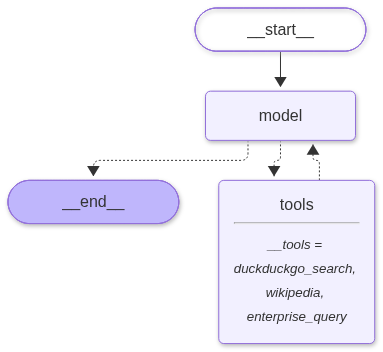

In [16]:
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model="gpt-5-mini",
    temperature=0.1,
    max_tokens=1000,
    timeout=30
)
agent = create_agent(model, tools=Toolkit)
agent

In [ ]:
example_query = input("Enter a query: ")

events = agent.stream(
    {"messages": [("user", example_query)]},
    stream_mode="values",
)
for event in events:
    event["messages"][-1].pretty_print()